
# Assessment 3 – Regression 2.1
## Predicting Goal Difference Using Linear Regression

**Prepared by:** Kshitiz

### Objective
The aim is to predict the goal difference between two opposing teams in the FIFA World Cup 2026 using eight pre-match explanatory variables.

The model uses 104 match records prepared in Regression 2.1 dataset preparation.

We will train and evaluate a multiple linear regression model using Python.


In [2]:

# Import libraries and load the prepared dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load Regression 2.1 dataset
df = pd.read_csv("../data/regression_2_1.csv")

print("Total matches:", len(df))
print("Dataset shape:", df.shape)

display(df.head())


Total matches: 104
Dataset shape: (104, 15)


,Date,Round,Home,Away,Home_Goals,Away_Goals,Goal_Difference,Prior_Goals_For_Diff,Prior_Goals_Against_Diff,Prior_Points_Per_Game_Diff,Prior_Win_Rate_Diff,Prior_Clean_Sheet_Rate_Diff,Rest_Days_Diff,Host_Nation_Advantage,Prior_Matches_Played_Diff
0,2026-06-11,Group stage,Mexico,South Africa,2,0,2,0.0,0.0,0.0,0.0,0.0,0,1,0
1,2026-06-11,Group stage,Korea Republic,Czechia,2,1,1,0.0,0.0,0.0,0.0,0.0,0,0,0
2,2026-06-12,Group stage,Canada,Bosnia–Herz,1,1,0,0.0,0.0,0.0,0.0,0.0,0,1,0
3,2026-06-12,Group stage,USA,Paraguay,4,1,3,0.0,0.0,0.0,0.0,0.0,0,1,0
4,2026-06-13,Group stage,Qatar,Switzerland,1,1,0,0.0,0.0,0.0,0.0,0.0,0,0,0



### 2. Model Training and Testing

This section develops a multiple linear regression model to predict goal difference between two teams.

The dataset is divided chronologically into 80% training data and 20% testing data.

The first 80% of matches are used to train the model, while the remaining 20% are used to evaluate its performance.

This approach helps prevent future match results from being used to train a model evaluated on earlier matches.


In [3]:

# Step 2: Train and test the regression model

# Select the eight explanatory variables
feature_columns = [
    "Prior_Goals_For_Diff",
    "Prior_Goals_Against_Diff",
    "Prior_Points_Per_Game_Diff",
    "Prior_Win_Rate_Diff",
    "Prior_Clean_Sheet_Rate_Diff",
    "Rest_Days_Diff",
    "Host_Nation_Advantage",
    "Prior_Matches_Played_Diff"
]

# Define explanatory variables (X) and target variable (y)
X = df[feature_columns]
y = df["Goal_Difference"]

# Split chronologically: 80% training, 20% testing
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train the multiple linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict goal differences for test matches
y_pred = model.predict(X_test)

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print("Model training completed successfully!")


Training matches: 83
Testing matches: 21
Model training completed successfully!



### 3. Model Evaluation

This section evaluates how accurately the regression model predicts goal difference.

Three performance measures are used:

- **MAE:** Average prediction error in goals. Lower is better.
- **RMSE:** Measures prediction errors, giving more weight to large mistakes. Lower is better.
- **R²:** Measures how well the model explains variation in goal difference. Higher is better.

We also compare the regression model against a simple baseline that predicts the average goal difference from the training data.


In [4]:

# Step 3: Evaluate the regression model

# Calculate model performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Baseline: predict the training-set average for every test match
baseline_pred = np.full(len(y_test), y_train.mean())

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

# Create a comparison table
evaluation = pd.DataFrame({
    "Model": ["Linear Regression", "Mean Baseline"],
    "MAE": [mae, baseline_mae],
    "RMSE": [rmse, baseline_rmse],
    "R2": [r2, baseline_r2]
})

print("Regression 2.1 - Model Evaluation")
display(evaluation.round(3))


Regression 2.1 - Model Evaluation


,Model,MAE,RMSE,R2
0,Linear Regression,1.644,2.062,-0.813
1,Mean Baseline,1.426,1.747,-0.302



**Interpretation of Model Evaluation**

The regression model is evaluated using MAE, RMSE and R² on 21 testing matches.

Its performance is compared with a baseline that predicts the average goal difference from the training matches.

Lower MAE and RMSE values indicate more accurate predictions. A higher R² indicates better explanatory performance.

The results help determine whether the eight pre-match variables improve prediction compared with the baseline.



**Interpretation of Model Evaluation**

The Linear Regression model achieved an MAE of 1.644, RMSE of 2.062 and R² of -0.813 on 21 test matches.

The baseline performed better, with an MAE of 1.426 and RMSE of 1.747. This indicates that the eight pre-match variables did not improve prediction accuracy in this test.

The negative R² suggests weak predictive performance. Possible reasons include limited historical data and the unpredictable nature of football matches.


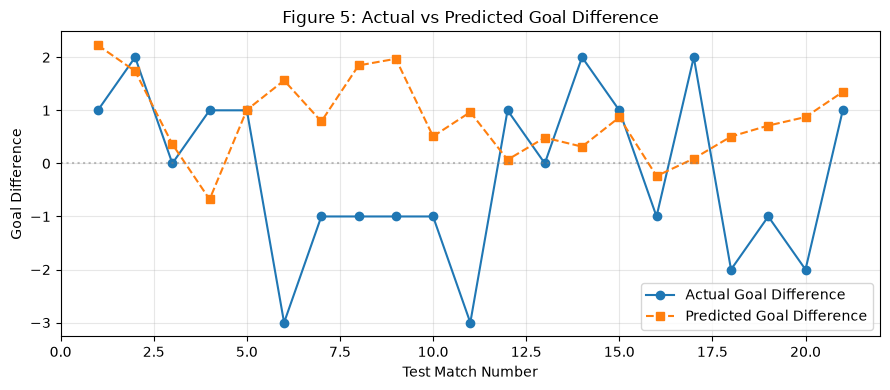

In [6]:

# Figure 5: Actual vs Predicted Goal Difference

plt.figure(figsize=(9, 4))

match_numbers = np.arange(1, len(y_test) + 1)

plt.plot(
    match_numbers, y_test.values,
    marker="o", label="Actual Goal Difference"
)

plt.plot(
    match_numbers, y_pred,
    marker="s", linestyle="--",
    label="Predicted Goal Difference"
)

plt.axhline(0, color="gray", linestyle=":", alpha=0.5)

plt.title("Figure 5: Actual vs Predicted Goal Difference")
plt.xlabel("Test Match Number")
plt.ylabel("Goal Difference")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### 5. Regression Coefficient Analysis

This section examines how the eight explanatory variables influence the predicted goal difference.

A positive coefficient indicates an increase in predicted goal difference when that variable increases, while a negative coefficient indicates a decrease, holding other variables constant.

The coefficients help explain the behaviour of the regression model. However, they do not necessarily represent causal relationships.


Regression Model Intercept: 0.568


,Variable,Coefficient
3,Prior_Win_Rate_Diff,-5.881
1,Prior_Goals_Against_Diff,-0.151
7,Prior_Matches_Played_Diff,0.000
0,Prior_Goals_For_Diff,0.119
5,Rest_Days_Diff,0.193
4,Prior_Clean_Sheet_Rate_Diff,0.640
6,Host_Nation_Advantage,1.112
2,Prior_Points_Per_Game_Diff,2.269


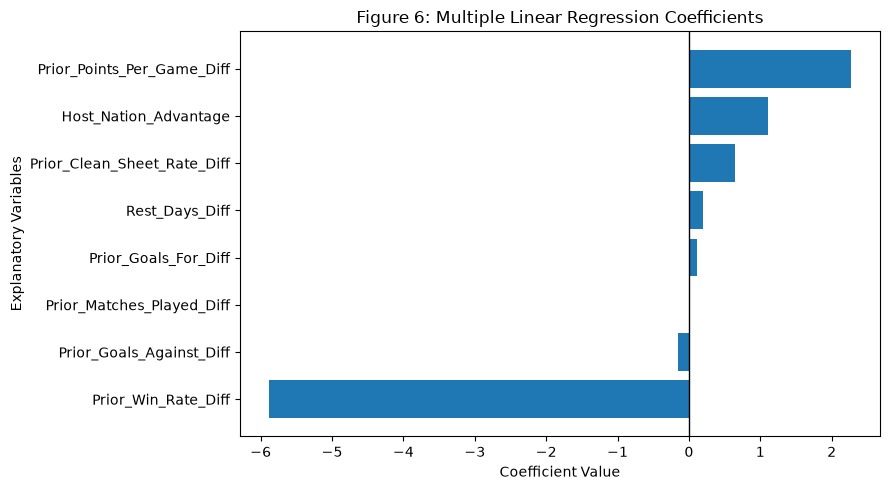

In [7]:

# Section 5: Regression Coefficient Analysis

# Create a table of regression coefficients
coefficient_df = pd.DataFrame({
    "Variable": feature_columns,
    "Coefficient": model.coef_
})

# Sort variables by coefficient value
coefficient_df = coefficient_df.sort_values(
    by="Coefficient"
)

print("Regression Model Intercept:",
      round(model.intercept_, 3))

display(coefficient_df.round(3))

# Figure 6: Regression coefficients
plt.figure(figsize=(9, 5))

plt.barh(
    coefficient_df["Variable"],
    coefficient_df["Coefficient"]
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Figure 6: Multiple Linear Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Explanatory Variables")
plt.tight_layout()
plt.show()


**Interpretation of Figure 6**

Figure 6 presents the coefficients of eight pre-match explanatory variables. Positive coefficients are associated with higher predicted goal differences, while negative coefficients are associated with lower predicted values. However, the results should be interpreted carefully because some predictors may be correlated, and their coefficients are measured on different scales.


### 6. Residual Analysis

Residual analysis examines the differences between actual and predicted goal differences.

A good regression model should have residuals scattered around zero without a clear pattern.

This analysis helps identify prediction errors, unusual matches and possible weaknesses in the model.


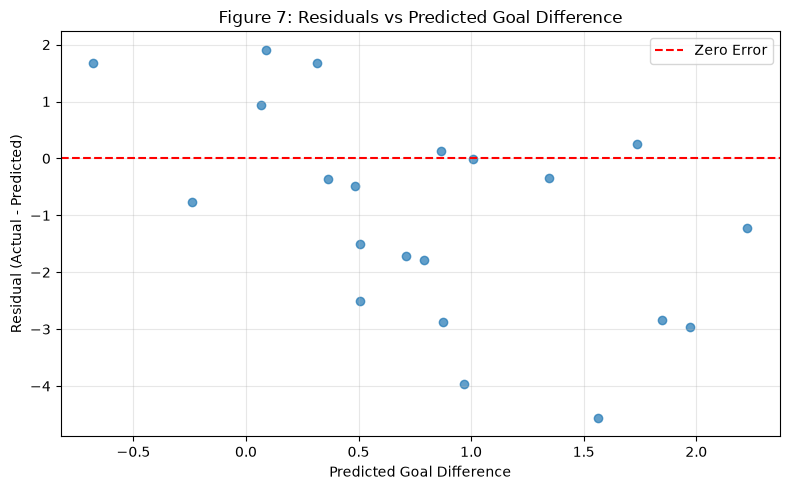

Mean residual: -1.016
Residual standard deviation: 1.794
Largest absolute error: 4.563


In [8]:

# Figure 7: Residual Analysis

# Calculate prediction errors
residuals = y_test.values - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.title("Figure 7: Residuals vs Predicted Goal Difference")
plt.xlabel("Predicted Goal Difference")
plt.ylabel("Residual (Actual - Predicted)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display residual statistics
print("Mean residual:", round(residuals.mean(), 3))
print("Residual standard deviation:", round(residuals.std(), 3))
print("Largest absolute error:", round(abs(residuals).max(), 3))



**Interpretation of Figure 7**

Figure 7 shows that the residuals are not evenly distributed around zero. The mean residual is -1.016, suggesting that the model generally overestimates goal difference in the test matches.

The residual standard deviation is 1.794, and the largest absolute prediction error is 4.563 goals.

These results indicate that the model has difficulty predicting some match outcomes accurately.



### 7. Predictor Correlation Analysis

This section examines the relationships between the eight explanatory variables.

A correlation coefficient close to +1 indicates a strong positive relationship, while a value close to -1 indicates a strong negative relationship.

Highly correlated predictors may cause multicollinearity, making regression coefficients less stable and difficult to interpret.


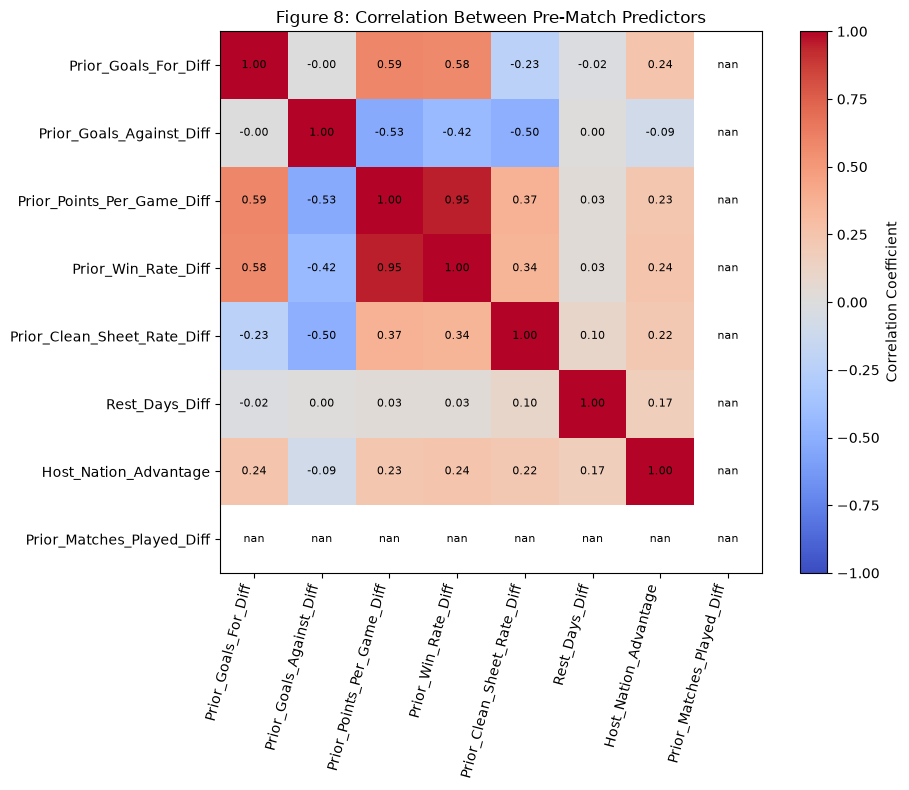

In [9]:

# Figure 8: Predictor Correlation Heatmap

# Calculate correlations using training data only
correlation_matrix = X_train.corr()

plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(feature_columns)),
    feature_columns,
    rotation=75,
    ha="right"
)

plt.yticks(
    range(len(feature_columns)),
    feature_columns
)

plt.title("Figure 8: Correlation Between Pre-Match Predictors")

# Add correlation values inside cells
for i in range(len(feature_columns)):
    for j in range(len(feature_columns)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()



**Interpretation of Figure 8**

Figure 8 shows the correlations between the eight pre-match explanatory variables.

Strong positive or negative correlations suggest that some predictors contain similar information.

This analysis helps identify possible multicollinearity, which may affect the stability and interpretation of the regression coefficients.



### 8. Conclusion

This task developed a multiple linear regression model to predict goal difference using 104 FIFA World Cup 2026 matches and eight pre-match explanatory variables.

The model was trained on 83 matches and tested on 21 matches. It achieved an MAE of 1.644, RMSE of 2.062 and R² of -0.813.

The model performed worse than the mean baseline, indicating limited predictive accuracy. Residual analysis also showed several large prediction errors.

Possible limitations include the small dataset, limited historical performance information and correlated predictors.

Future improvements could include pre-tournament FIFA rankings and previous international match results.
